# Who fits my build, by position (2026-11-16)

Every player who has played 5+ games this season, plotted by 9-cat value (x) against value in my build (y:
sum of PTS, AST, STL, 3PM, FT% z-scores). The dashed line is my 10th-best player by build value: anyone above it
would crack my top 10.

Groups: **Guards & wings** = eligible at PG, SG or SF. **PF** and **C** are separate. A player appears in every
group he is eligible for (a PF/C shows up in both PF and C; an SF/PF in both Guards & wings and PF).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'analysis'))
import trade_eval as te

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
SEASON, ME = 2027, 4
TARGETS = ['PTS', 'AST', 'STL', 'FG3M', 'FT']
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, MUTED, GRID, BASE, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'font.size': 10, 'legend.frameon': False, 'legend.labelcolor': INK2})

m = te.Model(te.load_player_seasons(SEASON - 8, SEASON), SEASON, TARGETS)
L = te.League(m, SEASON, ME, {})

def profile(r, team_id):
    pid = int(r.nba_player_id); t, age = m.talent(pid); cur = m.line(pid, SEASON)
    if t is None or cur is None or cur.GP < 5: return None
    z = m.z(t)
    return {'team_id': team_id, 'player': r.player_name, 'age': age, 'eligible': set(r.eligible_positions),
            'pos': '/'.join(p for p in ['PG', 'SG', 'SF', 'PF', 'C'] if p in r.eligible_positions),
            **{c: z['z_' + c] for c in te.CATS}, 'z9': z['z9'], 'zT': z['zT']}

ros = [profile(r, r.team_id) for _, r in L.rosters[L.rosters.nba_player_id.notna()].iterrows()]
fa = [profile(r, 0) for _, r in L.fa.iterrows()]
ALL = pd.DataFrame([p for p in ros + fa if p]).set_index('player')
ALL['owner'] = np.where(ALL.team_id == ME, 'you', np.where(ALL.team_id == 0, 'free agent', 'other team'))
ALL['team'] = ALL.team_id.map({**L.names, 0: 'free agent'})
mine = ALL[ALL.team_id == ME]
starters = mine.sort_values('zT', ascending=False).head(10)          # your top-10 by build value
BAR = starters.zT.min()
print(f'bar = your 10th-best player by build value: {starters.index[-1]} ({BAR:.2f})')

GROUPS = {'Guards & wings': {'PG', 'SG', 'SF'}, 'PF': {'PF'}, 'C': {'C'}}
for g, pos in GROUPS.items():
    ALL[g] = ALL.eligible.apply(lambda e: bool(e & pos))

bar = your 10th-best player by build value: Ajay Mitchell (-0.61)


In [2]:
summary = []
for g in GROUPS:
    d = ALL[ALL[g]]; fits = d[d.zT >= BAR]
    summary.append({'group': g, 'players': len(d), 'clear the bar': len(fits),
                    'on your team': int((fits.owner == 'you').sum()), 'free agents': int((fits.owner == 'free agent').sum()),
                    'other teams': int((fits.owner == 'other team').sum()),
                    'your players in group': int((d.owner == 'you').sum())})
summary = pd.DataFrame(summary).set_index('group')
display(summary)

,players,clear the bar,on your team,free agents,other teams,your players in group
group,,,,,,
Guards & wings,267,85,8,4,73,14
PF,113,22,2,0,20,4
C,83,7,0,0,7,2


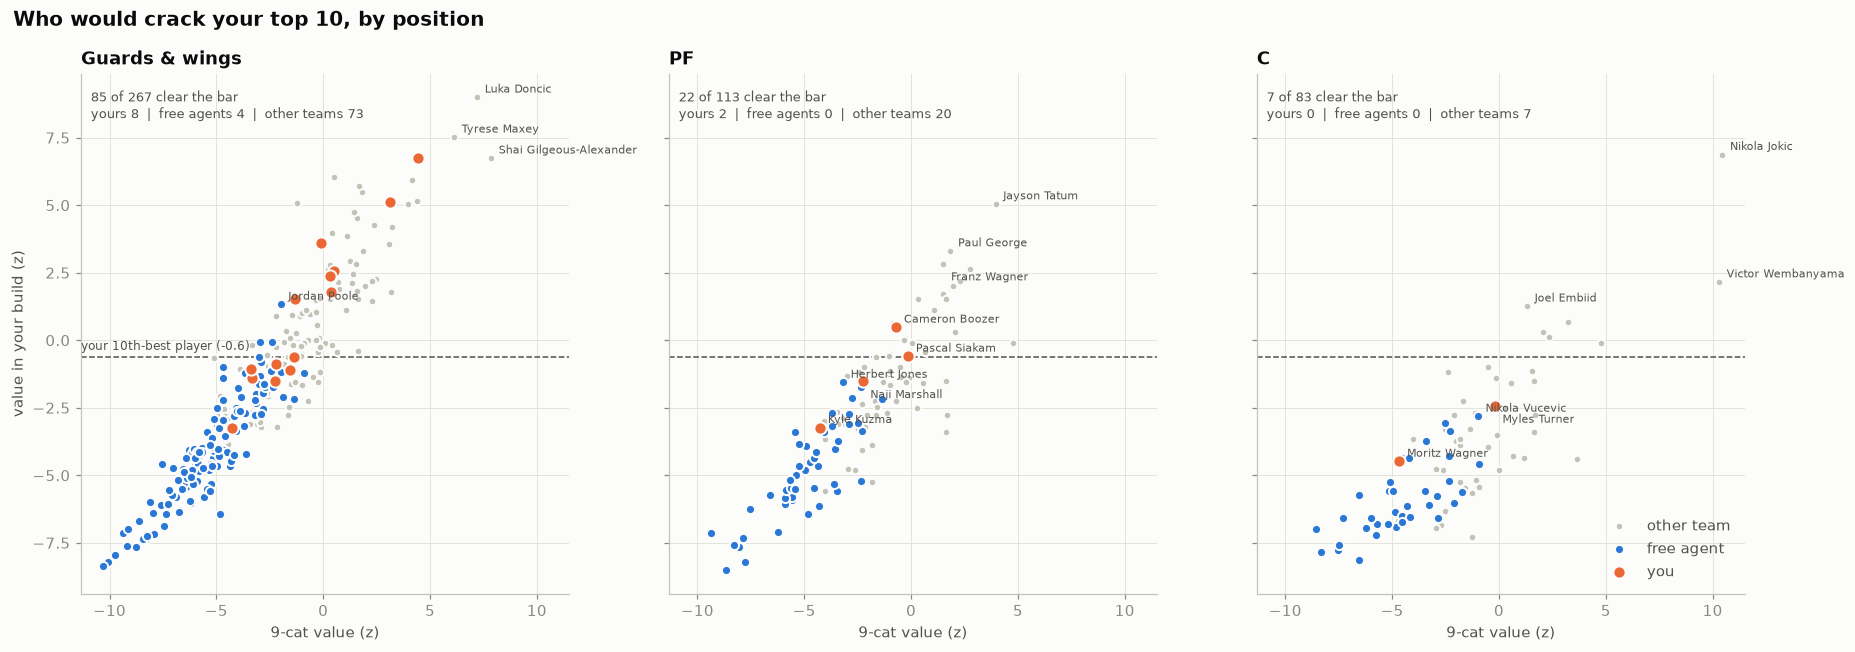

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 6), sharex=True, sharey=True)
for ax, g in zip(axs, GROUPS):
    d = ALL[ALL[g]]; fits = d[d.zT >= BAR].sort_values('zT', ascending=False)
    for own, col, sz in (('other team', BASE, 24), ('free agent', BLUE, 36), ('you', ORANGE, 64)):
        x = d[d.owner == own]
        ax.scatter(x.z9, x.zT, s=sz, color=col, edgecolor=SURF, linewidth=1.3, label=own, zorder=3)
    ax.axhline(BAR, color=INK2, lw=1, ls='--')
    # labels: best 3 fits on other teams, best free agent, and (outside the crowded guard chart) your players
    lab = [fits[fits.owner == 'other team'].head(3), d[d.owner == 'free agent'].nlargest(1, 'zT')]
    if g != 'Guards & wings': lab.append(d[d.owner == 'you'])
    placed = []
    for n, r in pd.concat(lab).iterrows():
        # nudge a label down when another label already sits close by
        dy = -11 if any(abs(r.z9 - x) < 1.2 and abs(r.zT - y) < 0.5 for x, y in placed) else 3
        ax.annotate(n, (r.z9, r.zT), xytext=(5, dy), textcoords='offset points', fontsize=7.5, color=INK2)
        placed.append((r.z9, r.zT))
    s = summary.loc[g]
    ax.text(0.02, 0.97, f"{s['clear the bar']} of {s.players} clear the bar\n"
                        f"yours {s['on your team']}  |  free agents {s['free agents']}  |  other teams {s['other teams']}",
            transform=ax.transAxes, ha='left', va='top', color=INK2, fontsize=8.5)
    ax.set_title(g); ax.set_xlabel('9-cat value (z)')
axs[0].set_ylabel('value in your build (z)')
axs[0].text(axs[0].get_xlim()[0], BAR + 0.25, f'your 10th-best player ({BAR:.1f})', color=INK2, fontsize=8)
axs[-1].legend(loc='lower right')
fig.suptitle('Who would crack your top 10, by position', x=0.01, ha='left', fontsize=13, fontweight='bold', color=INK)
plt.tight_layout(); plt.show()

In [ ]:
# the players behind the dots: everyone above the bar who is NOT on your team, by group
for g in GROUPS:
    d = ALL[ALL[g] & (ALL.zT >= BAR) & (ALL.owner != 'you')].sort_values('zT', ascending=False)
    print(f'\n{g}: {len(d)} players above the bar on other teams / free agency')
    
    display(d[['team', 'pos', 'age', 'PTS', 'AST', 'STL', 'FG3M', 'FT', 'zT', 'z9']].round(2).head(12))


Guards & wings: 77 players above the bar on other teams / free agency


,team,pos,age,PTS,AST,STL,FG3M,FT,zT,z9
player,,,,,,,,,,
Luka Doncic,H-Tine Astromechs,PG,27,2.91,2.32,1.39,2.37,-0.00,9.00,7.21
Tyrese Maxey,Team Youngbois😎,PG/SG,26,2.00,1.46,1.50,1.28,1.27,7.52,6.12
Shai Gilgeous-Alexander,Screwston Sweats,PG,28,2.57,1.34,0.67,0.23,1.93,6.74,7.86
Trae Young,TWIN FADE AWAY,PG,28,0.88,3.31,0.07,0.65,1.13,6.04,0.51
Cade Cunningham,H-Tine Astromechs,PG,25,1.59,3.01,0.55,0.37,0.43,5.94,4.15
LaMelo Ball,Team Youngbois😎,PG,25,0.91,1.81,0.60,2.01,0.36,5.70,1.66
James Harden,TWIN FADE AWAY,PG/SG,37,0.82,2.03,0.06,1.08,1.49,5.48,1.81
Jamal Murray,Seattle SuperSonics,PG,29,1.42,1.59,-0.17,1.30,1.01,5.16,4.37
Darius Acuff Jr.,Karaban Caravan,PG,20,1.61,1.82,-0.18,1.31,0.52,5.08,-1.23



PF: 20 players above the bar on other teams / free agency


,team,pos,age,PTS,AST,STL,FG3M,FT,zT,z9
player,,,,,,,,,,
Jayson Tatum,Screwston Sweats,SF/PF,28,1.64,1.41,-0.17,1.31,0.86,5.05,3.95
Paul George,Seattle SuperSonics,SF/PF,36,0.33,0.15,1.64,1.01,0.19,3.31,1.84
Franz Wagner,Jons of Soe Ingles,SF/PF,25,1.26,0.89,0.20,-0.16,0.65,2.84,1.51
Jalen Johnson,TWIN FADE AWAY,PF,24,0.95,1.94,0.29,-0.30,-0.27,2.62,2.78
Cooper Flagg,Naz Reid,SF/PF,19,1.00,0.72,0.68,-0.64,0.52,2.28,2.45
Kevin Durant,H-Tine Astromechs,SF/PF,38,1.33,0.32,-0.88,0.36,1.07,2.20,2.30
Lauri Markkanen,H-Tine Astromechs,SF/PF,29,1.15,-0.84,-0.56,1.14,1.11,2.00,1.94
LeBron James,TWIN FADE AWAY,SF/PF,41,0.77,1.96,0.12,-0.35,-0.77,1.73,1.48
Deni Avdija,Zebras,SF/PF,25,1.07,1.18,-0.36,0.13,-0.50,1.53,0.31



C: 7 players above the bar on other teams / free agency


,team,pos,age,PTS,AST,STL,FG3M,FT,zT,z9
player,,,,,,,,,,
Nikola Jokic,Ant's Unwanted Children,C,31,1.90,3.42,1.13,-0.10,0.52,6.87,10.46
Victor Wembanyama,Team Youngbois😎,C,22,1.70,-0.11,-0.05,0.42,0.19,2.16,10.30
Joel Embiid,Seattle SuperSonics,C,32,1.29,0.18,-0.98,-0.68,1.46,1.26,1.31
Karl-Anthony Towns,Jons of Soe Ingles,C,31,0.83,-0.27,-0.43,-0.05,0.60,0.67,3.21
Bam Adebayo,Jons of Soe Ingles,PF/C,29,0.56,-0.01,0.66,-0.43,-0.49,0.29,2.05
Alperen Sengun,Seattle SuperSonics,C,24,0.92,1.41,0.30,-1.02,-1.50,0.12,2.33
Anthony Davis,Naz Reid,PF/C,33,1.21,-0.40,0.23,-1.07,-0.08,-0.11,4.79
